# 03. E1 — автоматическая генерация и отбор признаков

**Вопрос:** можно ли не придумывать признаки вручную (E0), а сгенерировать их по шаблону и отобрать автоматически — без потери качества ранжирования?

**Как устроено:**
1. **Грамматика признаков** — признак = *ключ * фильтр событий * агрегат * окно* (как SQL-запрос  за последние N дней). Все признаки считаются по семействам и хранятся на диске в parquet (иначе не помещаются в 7.6 ГБ памяти на моем устройстве).
2. **Воронка отбора:** фильтры → ранжирование (SHAP, L1, gain) → жадный отбор по GAUC на val_a.
3. **Финальная модель** — тот же LightGBM (`LGB_PARAMS`), что в E0, на отобранном наборе; сравнение с E0 на val_a и val_b.

Генерацияи отбор запускались скриптами `scripts/build_e1_features.py` и `scripts/run_e1_selection.py` с контрольными точками (на случай падения WSL); здесь загружаем их результаты и обучаем финальные модели.

**Ограничение железа!!!!!:** без GPU, ~7.6 ГБ памяти — поэтому отбор идёт на "лёгкой" модели и подвыборке train (600 тыс. строк), а не перебором на полных данных.

In [ ]:
import sys, time, resource, pickle
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

import json
from src.candidates import load_candidates
from src.features import E0_FEATURES
from src.grammar import E1_DIR, FAMILIES, WINDOWS, AGGS, FILTERS
from src.metrics import evaluate
from src.models import LGB_PARAMS, train_lgb, make_logreg
from src.selection import catalog, load_matrix, fit_light

#куда будем сохранять результаты E1
ART = ROOT / "artifacts" / "E1"
#гд е хранятся прошлые по E0
ART0 = ROOT / "artifacts" / "E0"
with open(ART0 / "results.pkl", "rb") as f:
    E0 = pickle.load(f)

## 1. Грамматика признаков
как и в задании говорится, мы можем сделать уйму SELECT запросов с группировкой , фильтрами, окнами и агрегатами

**ключ**
-  `u` пользователь
-  `i` трек
-  `a` артист
- `ui` пользователь × трек
- `ua` пользователь × артист
-  `ul` пользователь × длина трека (короткие / средние / длинные) 


**фильтр** (какие события)
-  `all` все прослушивания
-  `reco` только рекомендации
-  `org` только органика 


**агрегат**
-  `cnt` число
-  `full` дослушиваний
- `skip` пропусков
-  `rate` доля дослушиваний
-  `srate` сглаженная доля
-  `played` суммарная доля прослушанного
- `like`, `dislike`, `days_since` дней с последнего события 


**окно** -  1, 3, 7, 14, 30, 90 дней и вся история 

Плюс 12 **сессионных** признаков (что происходило сегодня / за последний час до начала прослушивания).

Все признаки ключевых семейств считаются **на начало дня** кандидата (только события прошлых дней) — та же защита от утечки, что в E0 (тесты `tests/test_grammar.py`).

In [ ]:
cat = catalog()
print(f"Всего признаков в грамматике: {cat.height}")

#из каталога получили обьекты по family 
display(cat.group_by("family", maintain_order=True).len().rename({"len": "признаков"}))
#сколько признаков с каким агреготом без семейства сессионных
# в каталоге() отдельно обрабатывались сессионные призгнаки, там нет фильтров, окон и у каждой свое имя
display(cat.filter(pl.col("family") != "s").pivot(on="window", index="agg", values="feature", aggregate_function="len"))

Всего признаков в грамматике: 858


family,признаков
str,u32
"""u""",141
"""i""",141
"""a""",141
"""ui""",141
"""ua""",141
"""ul""",141
"""s""",12


agg,1d,3d,7d,14d,30d,90d,all,-
str,u32,u32,u32,u32,u32,u32,u32,u32
"""cnt""",18,18,18,18,18,18,18,0
"""full""",18,18,18,18,18,18,18,0
"""skip""",18,18,18,18,18,18,18,0
"""rate""",18,18,18,18,18,18,18,0
"""srate""",18,18,18,18,18,18,18,0
"""played""",18,18,18,18,18,18,18,0
"""like""",6,6,6,6,6,6,6,0
"""dislike""",6,6,6,6,6,6,6,0
"""since""",0,0,0,0,0,0,0,6


In [ ]:
# в журнале два прогона: после исправления утечки сессионные признаки 
# пересчитывались, а остальные семейства
# во втором прогоне пропускались (уже были на диске) 
# — берём полный расчёт каждого семейства (максимум по прогонам)

log = (pl.read_ndjson(E1_DIR / "build_log.jsonl")
       .group_by("family", maintain_order=True)
       .agg(pl.col("seconds", "peak_rss_gb").max()))

disk_gb = sum(p.stat().st_size for p in E1_DIR.glob("*.parquet")) / 1024**3
gen_time = log["seconds"].sum()


display(log.with_columns(pl.col("seconds", "peak_rss_gb").round(1)))
print(f"Генерация всех признаков: {gen_time:.0f} с, пик памяти {log['peak_rss_gb'].max():.1f} ГБ, на диске {disk_gb:.1f} ГБ")

family,seconds,peak_rss_gb
str,f64,f64
"""u""",3.1,1.7
"""i""",20.2,3.6
"""a""",7.0,3.6
"""ui""",28.6,4.0
"""ua""",28.3,4.8
"""ul""",4.2,4.8
"""s""",19.8,4.8


Генерация всех признаков: 111 с, пик памяти 4.8 ГБ, на диске 1.5 ГБ


## 2. Этап 1 воронки: фильтры

Смотрим на результат отбора признаков, почему некоторые признаки ушшли:
- **почти пустые** (> 99% пропусков) — например, органика по паре «пользователь * трек» за 1 день
- **константы**
- **почти-дубли** (|корреляция| > 0.98) — из пары оставляем более сильный по одномерному AUC. Пример: `cnt` и `full` за «всю историю» у трека почти пропорциональны

In [ ]:
#убраны с помощью stage_filter функции из файла run_e1_seelction
flt = json.loads((ART / "filter.json").read_text())
removed = pl.read_parquet(ART / "filter_removed.parquet").with_columns(
    pl.col("причина").str.replace(r"дубль .*", "дубль"))

print(f"{flt['all']} -> {len(flt['kept'])} признаков за {flt['seconds']:.0f} с")
#причина удаленных признаков
display(removed.group_by("причина").len().sort("len", descending=True))

858 → 666 признаков за 37 с


причина,len
str,u32
"""дубль""",174
"""константа""",14
"""почти пустой""",4


## 3. Этап 2: ранжирование признаков

Лёгкая модель (`LIGHT_PARAMS`) на всех 666 признаках, затем четыре способа упорядочить признаки:
- **SHAP внутри групп** — насколько признак *меняет порядок треков у одного пользователя за день* (std SHAP внутри группы «пользователь × день»)
- **SHAP общий** — вклад в прогноз в целом (в основном отличает дослушивающих пользователей от скипающих)
- **L1** — модуль веса в L1-логрегрессии 
- **gain** — встроенная важность LightGBM

**Стабильность:** тот же расчёт на другой подвыборке (seed 1) — насколько совпадают топы (коэффициент Жаккара: доля общих признаков)

In [ ]:
# если способ ранжирования хороший, он должен выбирать примерно 
# одни и те же признаки на разных выборках из одних данных

#смотрим на модели, которые были заупщены с помощью функций stage_rank в run_e1_selection
rank0 = pl.read_parquet(ART / "ranking.parquet")
rank1 = pl.read_parquet(ART / "ranking_seed1.parquet")
cost_rank = json.loads((ART / "ranking_cost.json").read_text())

def top(r, col, k):
    r = r.filter(pl.col("l1_abs") > 0) if col == "l1_abs" else r
    return set(r.sort(col, descending=True)["feature"][:k])

stab = pl.DataFrame([{"способ": n, **{f"Жаккар топ-{k}": round(len(top(rank0, c, k) & top(rank1, c, k)) / len(top(rank0, c, k) | top(rank1, c, k)), 2)
                                       for k in [20, 60]}}
                     for n, c in [("SHAP внутри групп", "shap_within"), ("SHAP общий", "shap_total"), ("L1", "l1_abs"), ("gain", "gain")]])
display(stab)
print(f"Стоимость: модель {cost_rank['fit_s']:.0f} с, SHAP {cost_rank['shap_s']:.0f} с, L1 {cost_rank['l1_s']:.0f} с")
display(rank0.sort("shap_within", descending=True).head(15).with_columns(pl.col(pl.Float64).round(4)))

способ,Жаккар топ-20,Жаккар топ-60
str,f64,f64
"""SHAP внутри групп""",0.67,0.64
"""SHAP общий""",0.6,0.48
"""L1""",0.6,0.29
"""gain""",0.74,0.85


Стоимость: модель 62 с, SHAP 9 с, L1 26 с


feature,shap_within,shap_total,l1_weight,l1_abs,gain
str,f64,f64,f64,f64,f64
"""s__hour_rate""",0.3993,0.919,0.4157,0.4157,496514.0198
"""s__today_reco_rate""",0.2488,0.4553,0.25,0.25,64814.7532
"""s__skip_streak""",0.2441,0.405,-0.3301,0.3301,96396.1228
"""s__prev_dur_min""",0.1314,0.1745,0.0702,0.0702,20010.8349
"""s__hour_cnt""",0.0987,0.1374,0.0,0.0,9085.8454
"""s__today_reco_cnt""",0.0545,0.0661,0.1372,0.1372,5431.7554
"""ul__reco_played__30d""",0.0449,0.1143,0.0,0.0,17925.7556
"""ul__reco_srate__90d""",0.0346,0.0987,0.0,0.0,11979.6537
"""ui__all_srate__all""",0.0308,0.0479,0.0908,0.0908,4188.6729


- L1 не стабилен на топ -60
- gain самый сильеый.ю но он измеряет, где модель делает сплиты, где отражается общий вклад, а не порядок треков внутри группы
- SHAP внутри  групп - стабилен и меряет как раз внутригрупповость

- сильный отрыв у сессионных признаков

## 4. сессионные признаки 



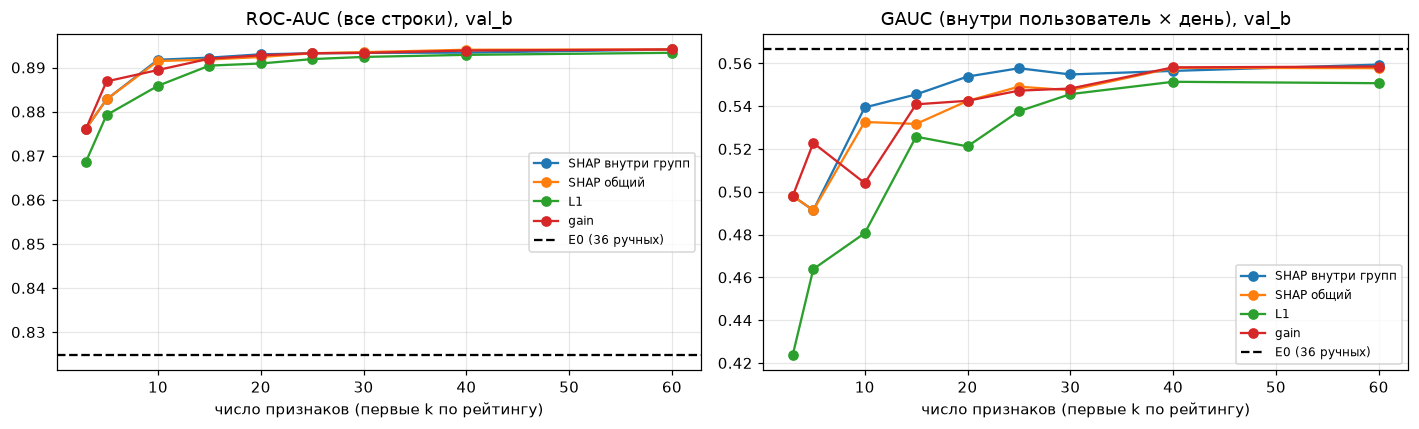

In [ ]:
#остатки с неверного run_e1_selection.py , работ шла 1.5 часа на железе, так что оставим как историю
#при перезапуске или воспроизведении эксперимента, все будет хорошо

#stage_parquet из run_e1_selection
curves = pl.read_parquet(ART / "curves.parquet").filter(
    (pl.col("part") == "val_b") & (pl.col("selector") != "жадный (GAUC)"))   # жадный тут был на неверном пуле 

e0c = curves.filter(pl.col("selector") == "E0 (ручные)")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))


for ax, m, title in [(axes[0], "roc_auc", "ROC-AUC (все строки)"), (axes[1], "gauc", "GAUC (внутри пользователь × день)")]:
    
    for sel in ["SHAP внутри групп", "SHAP общий", "L1", "gain"]:
        d = curves.filter(pl.col("selector") == sel).sort("k")
        ax.plot(d["k"], d[m], marker="o", label=sel)
    
    ax.axhline(e0c[m][0], color="black", ls="--", label="E0 (36 ручных)")
    ax.set_xlabel("число признаков (первые k по рейтингу)")
    ax.set_title(title + ", val_b")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

*левый график*
 - уже первые признаки давали большое значение, которые заниимают сессионные признаки


*правый график*
- только вот GAUC при них около 0.5, то есть как случайное угадывание
- **никто не догнал E0!!!!**

**Почему так** 
Сессионные признаки описывают момент, а в **GAUC** мы передаем группу пользователь * день
=> "среди треков одного человека сумела ли модель поставить понравившиеся выше непонравившихся"

- ROC - AUC нам пояснала вместе с лог лоссом - насколько вероятно, что жту строку дослушают, а GAUC правильно ли упорядочены треки одного человека
- сесионные признаки нам помогли во знание, что сейчас человек скипнет или нет, но не помогает выбрать между треками - что предложить




**Проверка** (`scripts/check_session_i7.py`): модель обучена с сессией, но при оценке всем строкам группы подставлено **одно** состояние сессии (как при реальном выборе):

In [ ]:
#файл выше написан
sc = pl.read_parquet(ART / "session_check.parquet").filter(~pl.col("model").str.starts_with("признак"))
display(sc.filter(pl.col("grouping") == "пользователь × день").select("model", "session_mode", pl.col("gauc").round(4), pl.col("ndcg@10").round(4)))
display(sc.filter(pl.col("session_mode") == "как есть").pivot(on="grouping", index="model", values="gauc").with_columns(pl.col(pl.Float64).round(4)))

model,session_mode,gauc,ndcg@10
str,str,f64,f64
"""E1 жадный (с сессией)""","""как есть""",0.6033,0.7826
"""E1 жадный (с сессией)""","""фиксирована: первое в группе""",0.5559,0.7613
"""E1 жадный (с сессией)""","""фиксирована: медиана группы""",0.5646,0.7632
"""E1 жадный (с сессией)""","""фиксирована: случайная строка группы""",0.5633,0.7624
"""E1 жадный без сессии""","""как есть""",0.5628,0.7609
"""E0""","""как есть""",0.5665,0.7629
"""E0 + сессия""","""как есть""",0.6061,0.7835
"""E0 + сессия""","""фиксирована: первое в группе""",0.5629,0.7641
"""E0 + сессия""","""фиксирована: медиана группы""",0.569,0.7651


model,пользователь × день,пользователь × час,пользователь × сессия
str,f64,f64,f64
"""E1 жадный (с сессией)""",0.6033,0.5591,0.5732
"""E1 жадный без сессии""",0.5628,0.5636,0.5633
"""E0""",0.5665,0.5667,0.5659
"""E0 + сессия""",0.6061,0.563,0.5764


- При фиксированном состоянии сессии выигрыш (+0.04 GAUC) **исчезает**
- В узких группах (пользователь × час) с сессией даже чуть хуже, чем без неё.
- в одном моменте (ts) **другие** признаки позволяют выбрать трек!

**Решение:** для задачи «ранжирование треков» сессионные признаки исключаются из отбора; их польза — предсказание пропуска, это отдельный результат

In [ ]:
# GAUC отдельных признаков как скора (без модели) — из того же session_check.parquet
single = (pl.read_parquet(ART / "session_check.parquet")
          .filter(pl.col("model").str.starts_with("признак"))
          .pivot(on="grouping", index="model", values="gauc")
          .with_columns(pl.col(pl.Float64).round(4)))
display(single)


model,пользователь × день,пользователь × час,пользователь × сессия
str,f64,f64,f64
"""признак s__today_rate""",0.4408,0.3168,0.3599
"""признак s__prev_dur_min""",0.5453,0.5144,0.5242
"""признак s__today_cnt""",0.485,0.4815,0.5011
"""признак ui__all_srate__all""",0.5445,0.5525,0.5513
"""признак i__all_srate__all""",0.5273,0.5204,0.5221


- группы сужаются слева направо : день - сессия - час
- `s__prev_dur_min` в группе «день» на уровне признаков трека, но внутри часа почти 0.5: он отличает **моменты дня**
- `s__today_cnt` +- 0.5 — для ранжирования бесполезен
- `s__today_rate` падает при сужении сильно, проверка на учетку в `check_r19_hot_hand.py` - как как -gauc = 0.71 - сильный рост, как будто утечка - выснено, что это артефакт метрики, а не ошибка в признаке


## 5. Этап 3: жадный отбор по GAUC на val_a (без сессии)

Пул — 60 лучших по **SHAP внутри групп** (самый стабильный и «ранжирующий» рейтинг). На каждом шаге пробуем добавить каждый признак пула, обучаем лёгкую модель и берём тот, что сильнее всего поднял GAUC на val_a. Отбор доведён до 15 признаков без порога остановки; число признаков выбираем по пику на val_a, а val_b — независимое подтверждение.

In [ ]:
# stage_greedy run_e1_selection
steps = json.loads((ART / "greedy_nosess.json").read_text())
gr = pl.DataFrame([{"шаг": s["step"], "признак": s["added"], "GAUC val_a": round(s["gauc"], 4), "прирост": round(s["gain"], 4),
                    "время, с": round(s["seconds"]), "2-е место": s["runner_up"][0]["feature"] if s["runner_up"] else ""} for s in steps])
display(gr)
greedy_time = sum(s["seconds"] for s in steps)
print(f"Время жадного отбора: {greedy_time / 60:.0f} мин, обучений лёгкой модели: {sum(s['fits'] for s in steps)}")

шаг,признак,GAUC val_a,прирост,"время, с",2-е место
i64,str,f64,f64,i64,str
1,"""ui__all_full__all""",0.5443,0.0443,123,"""ui__all_full__90d"""
2,"""i__all_srate__all""",0.5501,0.0058,113,"""i__reco_srate__90d"""
3,"""u__reco_skip__all""",0.5596,0.0095,127,"""u__reco_skip__90d"""
4,"""ui__all_played__90d""",0.5626,0.003,146,"""ui__all_srate__90d"""
5,"""ul__reco_srate__all""",0.5646,0.002,162,"""ul__all_srate__all"""
6,"""ua__all_played__all""",0.569,0.0045,148,"""ua__reco_played__all"""
7,"""ua__reco_full__all""",0.5703,0.0013,157,"""u__like__90d"""
8,"""ui__reco_srate__all""",0.5717,0.0014,164,"""i__reco_srate__90d"""
9,"""i__reco_srate__90d""",0.572,0.0003,161,"""i__reco_played__all"""


Время жадного отбора: 40 мин, обучений лёгкой модели: 795


### Кривая на val_a и val_b

Для каждого k обучаем лёгкую модель на первых k признаках жадного отбора и оцениваем на обеих частях. Если кривая на val_b идёт так же, как на val_a, отбор не переобучился на val_a.

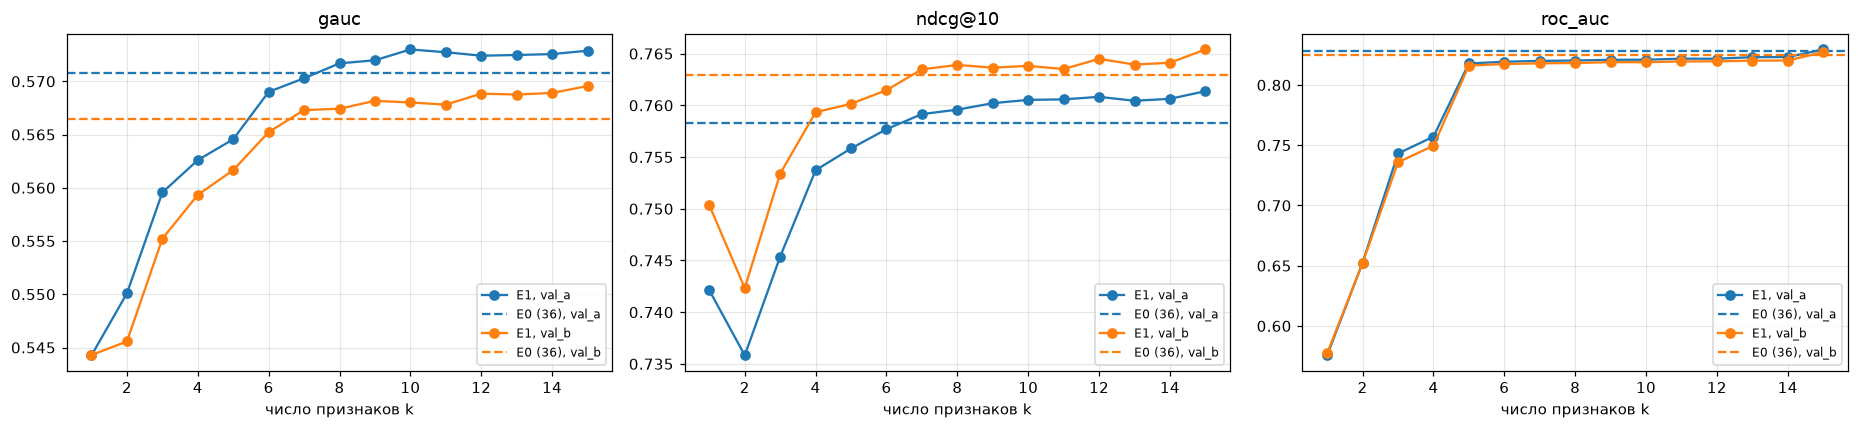

Пик GAUC на val_a при k = 10: 0.5730
Отобранные признаки: ['ui__all_full__all', 'i__all_srate__all', 'u__reco_skip__all', 'ui__all_played__90d', 'ul__reco_srate__all', 'ua__all_played__all', 'ua__reco_full__all', 'ui__reco_srate__all', 'i__reco_srate__90d', 'ui__all_full__90d']


In [ ]:
cands = load_candidates()
#выборка та же, что и в отборе sedd==0
#оп проверка, что и здесь val_a и в записанным жаным отбором резы одинаковые
tr_s = cands.filter(pl.col("part") == "train").sample(600_000, seed=0).sort("row_id")
va = cands.filter(pl.col("part") == "val_a")
vb = cands.filter(pl.col("part") == "val_b")
#в порядке добавления
chosen_all = [s["added"] for s in steps]
#36 ручныз признаков
feats0 = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")
#все что нужно для e0 и e1
Xs = {n: load_matrix(d, chosen_all, cat).join(feats0, on="row_id", how="left", maintain_order="left")
      for n, d in [("tr", tr_s), ("va", va), ("vb", vb)]}

#функция одной точки
rows = []
def light_eval(name, k, cols):
    m = fit_light(Xs["tr"].select(cols).to_numpy(), tr_s["label"].to_numpy(), Xs["va"].select(cols).to_numpy(), va["label"].to_numpy())
    for part, d, key in [("val_a", va, "va"), ("val_b", vb, "vb")]:
        p = m.predict(Xs[key].select(cols).to_numpy(), num_iteration=m.best_iteration)
        rows.append({"набор": name, "k": k, "часть": part, **evaluate(d.select("uid", "day", "label").with_columns(p=pl.Series(p)), "p")})

#точки кривой
for k in range(1, len(chosen_all) + 1):
    light_eval("E1 жадный", k, chosen_all[:k])
# у нее же не меняем никаких k, не обучаем, так как она готова,
#  и поэтому это горизональная линия на рисунке
light_eval("E0", len(E0_FEATURES), E0_FEATURES)
light = pl.DataFrame(rows)


e0l = light.filter(pl.col("набор") == "E0")
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, m in zip(axes, ["gauc", "ndcg@10", "roc_auc"]):
    for part, c in [("val_a", "C0"), ("val_b", "C1")]:
        
        d = light.filter((pl.col("набор") == "E1 жадный") & (pl.col("часть") == part)).sort("k")
        ax.plot(d["k"], d[m], marker="o", color=c, label=f"E1, {part}")
        ax.axhline(e0l.filter(pl.col("часть") == part)[m][0], color=c, ls="--", label=f"E0 (36), {part}")
    
    ax.set_xlabel("число признаков k")
    ax.set_title(m)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


va_curve = light.filter((pl.col("набор") == "E1 жадный") & (pl.col("часть") == "val_a")).sort("k")
K_BEST = int(va_curve.sort("gauc", descending=True)["k"][0])
SELECTED = chosen_all[:K_BEST]
print(f"Пик GAUC на val_a при k = {K_BEST}: {va_curve.filter(pl.col('k') == K_BEST)['gauc'][0]:.4f}")
print("Отобранные признаки:", SELECTED)

- почти все качество дают перве 7 признаков, а потом плато
- отбор не переобучился наа val_a!!!
- набор вышел сильный в ранжровании треков
- но послабее в вероятностях - кто перед нами, какой пользователь

## 6. Финальные модели

Те же модели и параметры, что в E0 (`LGB_PARAMS`, ранняя остановка по val_a; логрегрессия `make_logreg`), но на **полном** train:
- **E1** — только автоматически отобранные признаки;
- **E0 + E1** — ручные плюс отобранные: даёт ли автоматика что-то сверх ручных признаков.

In [ ]:
del Xs
parts = {p: cands.filter(pl.col("part") == p) for p in ["train", "val_a", "val_b"]}
union = [*E0_FEATURES, *[f for f in SELECTED if f not in E0_FEATURES]]

t0 = time.perf_counter()
M = {p: load_matrix(d, SELECTED, cat).join(feats0, on="row_id", how="left", maintain_order="left") for p, d in parts.items()}
load_time = time.perf_counter() - t0
y = {p: d["label"].to_numpy() for p, d in parts.items()}


models, cost = {}, {"load_s": load_time}
for name, cols in [("E1", SELECTED), ("E0 + E1", union)]:
    m, hist, sec = train_lgb(M["train"].select(cols).to_numpy(), y["train"], M["val_a"].select(cols).to_numpy(), y["val_a"])
    models[name] = (m, cols)
    cost[f"lgb_{name}_s"] = sec
    print(f"LightGBM {name}: {len(cols)} признаков, {m.best_iteration} деревьев, {sec:.0f} с")


t0 = time.perf_counter()
lr_model = make_logreg(SELECTED).fit(M["train"].select(SELECTED).to_numpy(), y["train"])
cost["lr_E1_s"] = time.perf_counter() - t0

print(f"Логрегрессия E1: {cost['lr_E1_s']:.0f} с; пиковая память: {peak_ram_gb():.1f} ГБ")

LightGBM E1: 10 признаков, 123 деревьев, 21 с


LightGBM E0 + E1: 46 признаков, 209 деревьев, 51 с


Логрегрессия E1: 5 с; пиковая память: 3.3 ГБ


In [ ]:
rows, preds = [], []

for p in ["val_a", "val_b"]:
    d = parts[p].select("row_id", "uid", "day", "part", "label").with_columns(
        **{f"p_{n}": pl.Series(m.predict(M[p].select(cols).to_numpy(), num_iteration=m.best_iteration)) for n, (m, cols) in models.items()},
        p_lr=pl.Series(lr_model.predict_proba(M[p].select(SELECTED).to_numpy())[:, 1]))
    preds.append(d)
    
    for name, col in [("E1 LightGBM", "p_E1"), ("E0 + E1 LightGBM", "p_E0 + E1"), ("E1 логрегрессия", "p_lr")]:
        rows.append({"модель": name, "часть": p, **evaluate(d, col)})


preds = pl.concat(preds)
e0m = E0["metrics"].filter(pl.col("модель").is_in(["LightGBM", "логрегрессия"])).with_columns(
    ("E0 " + pl.col("модель")).alias("модель"))
metrics = pl.concat([e0m.select(pl.DataFrame(rows).columns), pl.DataFrame(rows)], how="vertical_relaxed")

display(metrics.sort("часть", "модель").with_columns(pl.col(c).round(4) for c in ["logloss", "roc_auc", "gauc", "ndcg@10", "recall@10"]))

модель,часть,logloss,roc_auc,ndcg@10,recall@10,gauc,groups
str,str,f64,f64,f64,f64,f64,i64
"""E0 + E1 LightGBM""","""val_a""",0.4554,0.832,0.7635,0.5152,0.5765,15808
"""E0 LightGBM""","""val_a""",0.4584,0.8294,0.761,0.5143,0.574,15808
"""E0 логрегрессия""","""val_a""",0.4688,0.8227,0.7526,0.511,0.5657,15808
"""E1 LightGBM""","""val_a""",0.4678,0.8212,0.7616,0.5143,0.5725,15808
"""E1 логрегрессия""","""val_a""",0.4776,0.8144,0.7527,0.5107,0.5645,15808
"""E0 + E1 LightGBM""","""val_b""",0.4524,0.8286,0.7672,0.512,0.5733,15622
"""E0 LightGBM""","""val_b""",0.4558,0.8254,0.7651,0.5104,0.569,15622
"""E0 логрегрессия""","""val_b""",0.4651,0.8192,0.7577,0.5062,0.5623,15622
"""E1 LightGBM""","""val_b""",0.4633,0.819,0.7645,0.51,0.5692,15622


### Значима ли разница с E0?

Разница GAUC на val_b невелика, поэтому оцениваем шум: **парный бутстреп по группам** «пользователь × день» (1000 раз выбираем группы с возвращением и считаем среднюю разницу GAUC E1 − E0 на одних и тех же группах). Если 95%-интервал не содержит 0 — разница не случайна.

In [ ]:
#если взять человека в один день, если взять его дослушанный и его скипнутый трек,
#  модель поставила дослуашнный выше?
def group_gauc(d, col):
    return (
        # как и в metrics.py считаем,
        d.with_columns(r=pl.col(col).rank("average").over("uid", "day"),
                           npos=pl.col("label").sum().over("uid", "day"),
                             n=pl.len().over("uid", "day"))

            .filter((pl.col("npos") > 0) & (pl.col("npos") < pl.col("n")))
            .group_by("uid", "day")
            .agg(g=((pl.col("r") * pl.col("label")).sum() - pl.col("npos").first() * (pl.col("npos").first() + 1) / 2)
                 / (pl.col("npos").first() * (pl.col("n").first() - pl.col("npos").first())))
            .sort("uid", "day")["g"].to_numpy())


#собираем все обученные модели
#left - сохраняем порядок строк
vb_p = (preds.filter(pl.col("part") == "val_b")
        .join(E0["predictions"].select("row_id", pl.col("p_lgb").alias("p_E0")), on="row_id", how="left", maintain_order="left"))
base = group_gauc(vb_p, "p_E0")
#матрица 1000 на len(abse) - каждая строка - один воображаемый val_b
# с возвращаением!
idx = np.random.default_rng(0).integers(0, len(base), (1000, len(base)))

boot = []
for name, col in [("E1 − E0", "p_E1"), ("(E0 + E1) − E0", "p_E0 + E1")]:
    diff = group_gauc(vb_p, col) - base
    bs = diff[idx].mean(1) #среднее по строке
    boot.append({"сравнение": name, "разница GAUC": round(diff.mean(), 4),
                 "95% ДИ": f"[{np.quantile(bs, 0.025):+.4f}; {np.quantile(bs, 0.975):+.4f}]"})
boot = pl.DataFrame(boot)
boot

сравнение,разница GAUC,95% ДИ
str,f64,str
"""E1 − E0""",0.0002,"""[-0.0025; +0.0028]"""
"""(E0 + E1) − E0""",0.0043,"""[+0.0021; +0.0064]"""


- ноль внутри -> различие неотличимо от шума
- весь интервал >0 - прирост реальный

- 10 автоматических признаков ранжируют так же, как и 36 ручных
- добавление автоматических признаков к ручным дает настоящий прирост

## 7. Стоимость

Время на этом ноутбуке (CPU, 10 потоков). У E1 основная цена — **поиск** (ранжирование + жадный отбор); после того как набор найден, расчёт признаков и обучение дешевле, чем у E0, потому что признаков меньше.

In [13]:
cost_tab = pl.DataFrame([
    {"этап": "генерация признаков (все семейства)", "E0": E0["cost"]["feature_time_s"], "E1": gen_time},
    {"этап": "фильтры", "E0": None, "E1": flt["seconds"]},
    {"этап": "ранжирование (модель + SHAP + L1)", "E0": None, "E1": cost_rank["fit_s"] + cost_rank["shap_s"] + cost_rank["l1_s"]},
    {"этап": "жадный отбор", "E0": None, "E1": greedy_time},
    {"этап": "обучение LightGBM (полный train)", "E0": E0["cost"]["lgb_train_s"], "E1": cost["lgb_E1_s"]},
    {"этап": "обучение логрегрессии", "E0": E0["cost"]["lr_train_s"], "E1": cost["lr_E1_s"]},
]).with_columns(pl.col("E0", "E1").round(0))
display(cost_tab)
print(f"Признаков в модели: E0 {len(E0_FEATURES)}, E1 {len(SELECTED)}; на диске грамматика занимает {disk_gb:.1f} ГБ")

этап,E0,E1
str,f64,f64
"""генерация признаков (все семейства)""",39.0,111.0
"""фильтры""",null,37.0
"""ранжирование (модель + SHAP + L1)""",null,97.0
"""жадный отбор""",null,2392.0
"""обучение LightGBM (полный train)""",51.0,21.0
"""обучение логрегрессии""",24.0,5.0


Признаков в модели: E0 36, E1 10; на диске грамматика занимает 1.5 ГБ


## 8. Сохранение результатов

`artifacts/E1/`: `results.pkl` (метрики, признаки, кривые, бутстреп, стоимость, предсказания), `lgb.pkl`, `lgb_union.pkl`, `lr.pkl`.

In [14]:
results = {
    "experiment": "E1",
    "features": SELECTED, "k_best": K_BEST, "greedy_steps": steps, "union_features": union,
    "lgb_params": LGB_PARAMS,
    "best_iteration": {n: m.best_iteration for n, (m, _) in models.items()},
    "metrics": metrics, "light_curve": light, "bootstrap": boot,
    "predictions": preds,
    "cost": {**cost, "generation_s": gen_time, "filter_s": flt["seconds"], "greedy_s": greedy_time,
             "rank_s": cost_rank["fit_s"] + cost_rank["shap_s"] + cost_rank["l1_s"],
             "peak_ram_gb": peak_ram_gb(), "n_features": len(SELECTED), "disk_gb": disk_gb},
}
for name, obj in [("results.pkl", results), ("lgb.pkl", models["E1"][0]), ("lgb_union.pkl", models["E0 + E1"][0]), ("lr.pkl", lr_model)]:
    with open(ART / name, "wb") as f:
        pickle.dump(obj, f)
display(results["cost"])

{'load_s': 4.83845844300231,
 'lgb_E1_s': 21.423879030000535,
 'lgb_E0 + E1_s': 51.40167536399531,
 'lr_E1_s': 5.392463827003667,
 'generation_s': 111.22358859400083,
 'filter_s': 36.61383896699954,
 'greedy_s': 2391.875686435,
 'rank_s': 96.8909563140005,
 'peak_ram_gb': 3.2687110900878906,
 'n_features': 10,
 'disk_gb': 1.4646024517714977}

## 9. Выводы

**Главный результат (val_b, полный LightGBM с параметрами E0):**

| модель | признаков | LogLoss | ROC-AUC | GAUC | NDCG@10 |
|---|---|---|---|---|---|
| E0 (ручные) | 36 | 0.456 | 0.825 | 0.569 | 0.765 |
| **E1 (автоматические)** | **10** | 0.463 | 0.819 | **0.569** | 0.765 |
| E0 + E1 | 46 | **0.452** | **0.829** | **0.573** | **0.767** |

1. Автоматика заменяет ручные признаки без потери качества ранжирования
2. **Вместе с ручными автоматика даёт небольшой, но значимый прирост:**. Грамматика нашла то, чего нет в E0: длинные окна (90 дней, вся история), отдельные срезы по рекомендациям (`reco`) и связку «пользователь × длина трека» (`ul`).
3. **По LogLoss/ROC-AUC E1 один хуже E0:** отбор по GAUC не берёт признаки «насколько пользователь вообще дослушивает» — внутри группы они не ранжируют, но нужны для точных вероятностей. Отбор оптимизирует ровно ту метрику, которую ему дали.

4. **Способ отбора критичен.** Рейтинги по SHAP общему / L1 / gain тянут наверх сессионные признаки и дают высокий ROC-AUC при плохом GAUC (раздел 4). Для ранжирования работает только связка «SHAP внутри групп → жадный отбор по GAUC». Самый стабильный рейтинг — gain (Жаккар топ-60 0.85), но он стабилен в выборе «не тех» признаков; среди «ранжирующих» рейтингов стабильнее всех SHAP внутри групп (0.64).


**Цена:** основная стоимость E1 — поиск: жадный отбор ~40 мин (795 обучений лёгкой модели) против нуля у E0, плюс 1.5 ГБ признаков на диске. 

**Ограничения:** отбор на подвыборке train (600 тыс.) и лёгкой модели из-за памяти; пул — 60 признаков из 666; один прогон отбора (стабильность самого жадного выбора по разным seed не проверялась). Сессионные признаки исключены из задачи ранжирования 
